# Tehtävä 5: Clustering and association rule mining

Tehtävässä on kaksi erillistä osaa, joista kumpikin on toteutettu erikseen CRISP-DM-mallilla selkeyden vuoksi.

## Osa 1. Finding optimal hub locations  
Eli optimaalisten tukikohtien sijaintien löytäminen.  

### 1.1 Tavoitteen määrittäminen
*Business Understanding*  

Tavoitteena on löytää drone-toimitusyritykselle optimaaliset sijainnit keskuksille tai varikoille, joissa droneja säilytetään, huolletaan ja pakataan tuotteiden kuljetusta varten. Tutkitaan sijaintien paikkaa k-means-algoritmin avulla, joka myöhemmin korvataan hierarkkisella klusteroinnilla.  

### 1.2. Datan keräys ja tutkiminen
*Data Understanding*  

Käytetään datasettinä asiakkaiden sijainteja. Datasetissä on seuraavat sarakkeet: `clientid`: uniikki ID kullekin asiakkaalle, `x`: x-koordinaatti asiakkaan sijainnista ja `y`: asiakkaan sijainnin y-koordinaatti.  

In [1]:
import pandas as pd

# Ladataan datasetti
cust_locations = pd.read_csv("datasets/drone_cust_locations.csv", sep=";")
cust_locations

,clientid,x,y
0,1,622.771572,164.857623
1,2,416.357298,630.193634
2,3,292.735020,567.333231
3,4,737.211288,166.225676
4,5,540.475375,682.912298
...,...,...,...
5951,5952,832.857394,616.861410
5952,5953,242.734500,490.325092
5953,5954,108.690847,758.833921
5954,5955,803.251074,430.740623


In [2]:
print(cust_locations.columns) # tulostetaan sarakkeiden nimet

Index(['clientid', 'x', 'y'], dtype='str')


Datasetissä on 5956 näytettä.

### 1.3. Datan valmistelu
*Data Preparation*  

Visualisoidaan asiakkaiden sijainnit kaksiulotteisena. Käytetään Pandasin scatter plotia. Sitä ennen clientid-sarake täytyy poistaa datasetistä, sillä sitä ei tarvitse plottaukseen. Käytännössä siis luodaan uusi datasetti ilman id-saraketta.

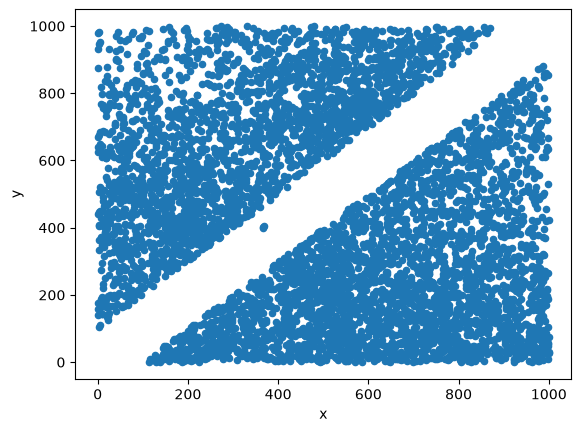

In [3]:
import numpy as np

# Poistetaan id-sarake
df = cust_locations.drop(columns="clientid")

df.plot.scatter(x="x", y="y");

Sijainnit ovat mielenkiintoisesti jakautuneet, selvästi kahteen erilliseen osaan. Kuvaajan keskellä on lähes tyhjä kaistale vasemmasta alakulmasta oikeaan yläkulmaan. Eli datasetissä ei ole juuri yhtään näytettä, joissa x:n ja y:n arvo on suunnilleen sama. Toisin sanoen suoran y=x lähistöllä pisteitä ei juurikaan ole.  

Tarkistetaan vielä koordinaattien arvoja, mm. keskiarvo, minimi ja maksimi, jotta varmistetaan, että koordinaattipisteet on oikein luettu ja plotattu.

In [4]:
print(cust_locations[["x", "y"]].describe())

                 x            y
count  5956.000000  5956.000000
mean    508.823177   427.554772
std     271.061462   289.044640
min       0.017692     0.043285
25%     282.582920   170.079921
50%     518.100892   397.786441
75%     727.156497   669.982518
max     999.533215   999.731720


Molemmissa sarakkeissa minimiarvo on lähes 0, ja maksimiarvo lähes 1000, joten voi olettaa kuvaajan asteikon olevan oikea. X-koordinaatin keskiarvo on noin 508 ja y-koordinaatin 427. Tästä voi päätellä, että sijainnit eivät ole tavanomaisia maantieteellisiä koordinaatteja, vaan skaalattu noin 1000x1000 yksikön kokoiselle alueelle.

### 1.4. Mallinnus
*Modeling*  

Etsitään optimaaliset sijainnit kolmelle drone-varikolle k-means-algoritmin avulla. Jokaisen varikon tarkoituksena on palvella sen ympärillä olevia asiakkaita.

In [5]:
from sklearn.cluster import KMeans

cluster_count=3

model = KMeans(init='random', n_clusters=cluster_count, random_state=37) # luodaan malli
model.fit(df) # koulutetaan malli

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'random'
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",37
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 2)","[[19

Tulostetaan klustereiden otsikot:

In [6]:
labels = model.labels_
np.unique(labels)

array([0, 1, 2], dtype=int32)

Klusterit ovat 0, 1 ja 2. Liitetään klusteritieto alkuperäiseen datasettiin, eli lisätään yksi sarake.

In [7]:
# Luodaan uusi datasetti kopioimalla alkuperäinen
locations_df = cust_locations

# Liitetään varikko-array osaksi uutta datasettiä
locations_df["depot"] = labels
locations_df[:10] # tulostetaan 10 ensimmäistä riviä

,clientid,x,y,depot
0,1,622.771572,164.857623,2
1,2,416.357298,630.193634,1
2,3,292.735020,567.333231,0
3,4,737.211288,166.225676,2
4,5,540.475375,682.912298,1
5,6,535.469492,318.439661,2
6,7,640.380050,870.833221,1
7,8,235.772075,359.048203,0
8,9,481.896884,661.491838,1
9,10,730.032789,312.177817,2


In [8]:
# Lasketaan ja tulostetaan klustereiden sijainnit eli koordinaatit
cluster_centers = model.cluster_centers_
cluster_centers

array([[196.6886209 , 385.27554342],
       [548.74574036, 787.53638871],
       [700.47724087, 211.35964294]])

Plotataan klusterikeskukset jotta hahmotetaan ne visuaalisesti. Muutetaan ensin klusterikeskus-array datasetiksi (pandasin dataframe).

In [9]:
centers_df = pd.DataFrame(cluster_centers, columns=["x", "y"])
print(centers_df)                          

            x           y
0  196.688621  385.275543
1  548.745740  787.536389
2  700.477241  211.359643


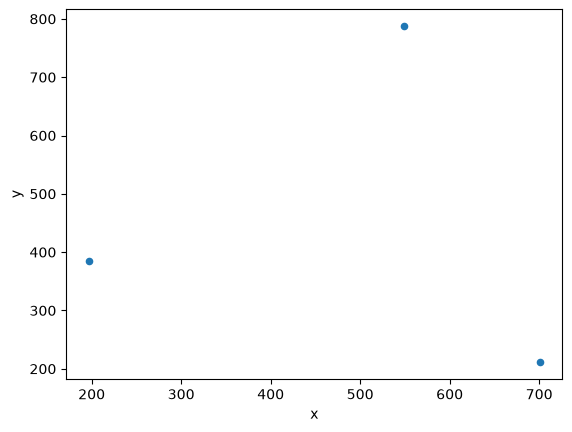

In [10]:
centers_df.plot.scatter(x="x", y="y");

Mallin ennustamat optimaaliset varikot ovat selvästi toisista erillään. Seuraavaksi luodaan värikoodattu scatterplot, jossa eri varikkoon kuuluvat sijainnit ovat eri värillä. Varikot on merkitty punaisella X:llä.

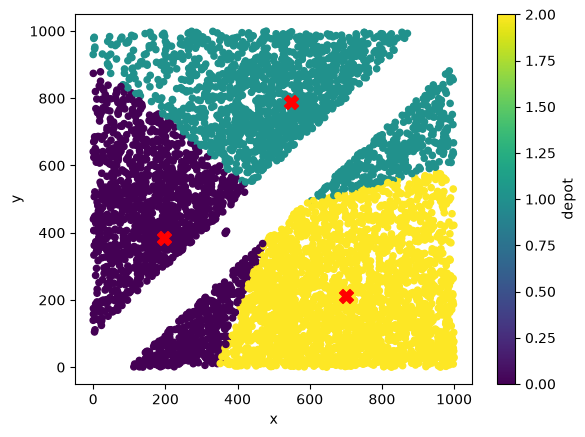

In [11]:
ax = locations_df.plot.scatter(x="x", y="y", c="depot", cmap="viridis")

ax.scatter(
    centers_df["x"],
    centers_df["y"],
    color="red",
    marker="X",
    s=100
)

#### Varikoiden lukumäärä
Kokeillaan eri KMeansin parametrin `n_clusters` arvolla, jota varten on aiemmin luotu muuttuja `cluster_count`. Säilytetään sama `random_state`:n arvo kuin aiemmin.  

##### Viisi varikkoa

In [12]:
cluster_count=5

model = KMeans(init='random', n_clusters=cluster_count, random_state=37)
model.fit(df)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'random'
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",37
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 2)","[[16

Varikoiden sijainnit:  [[161.51567842 497.2944601 ]
 [436.5817034  148.41581264]
 [803.38511517 151.57378802]
 [488.82145603 825.33790596]
 [807.39493983 531.37932375]]


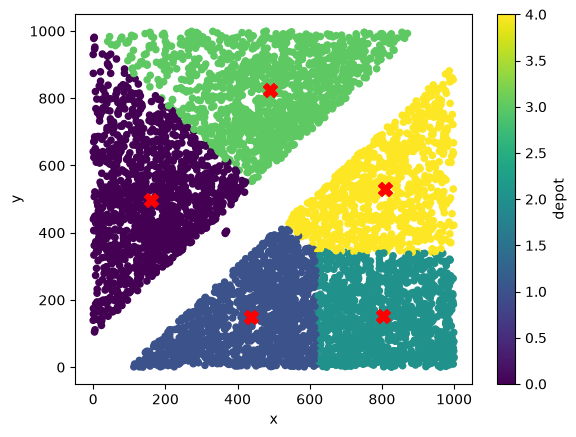

In [13]:
# Päivitetään klusteriluokat dataframeen
labels = model.labels_
locations_df["depot"] = labels

# Lasketaan uudet klusterikeskukset
cluster_centers = model.cluster_centers_
print("Varikoiden sijainnit: ", cluster_centers)

# Päivitetään klusterikeskusten (varikoiden) dataframe
centers_df = pd.DataFrame(cluster_centers, columns=["x", "y"])

# Plotataan pisteet ja uudet varikot
ax = locations_df.plot.scatter(x="x", y="y", c="depot", cmap="viridis")

ax.scatter(
    centers_df["x"],
    centers_df["y"],
    color="red",
    marker="X",
    s=100
)


Plotatussa kuvassa nähdään viiden varikon sijainnit. Jälleen näyttää siltä, että klusterikeskukset ovat melko keskellä palveltavia sijainteja. Varikoiden otsikot ovat 0, 1, 2, 3 ja 4, joista kunkin väri näkyy kuvan asteikolla. Esimerkiksi varikko 0 on violetti ja varikko 1 tummempi sininen.

##### 10 varikkoa
Muokkasin parametrin `cluster_count` arvoksi 10. Algoritmi toimi oletetusti ja loi varikot otsikoilla 0..9. Tähän soluun asti koko tehtävän ajamiseen kestää sekä viiden että kymmenen varikon tapauksessa 10 sekuntia. Notebook ei mittaa tarkempaa aikaa, joten ihmissilmälle laskenta-ajassa ei ole eroa. Kuitenkin jos tutkisi tarkemmin, laskenta-ajoissa voisi olla hyvin pieniä eroja.

#### Hierarkkinen klusterointi (agglomerative hierarchical clustering)
Seuraavaksi vaihdetaan k-means-algoritmi sklearn-kirjaston AgglomerativeClustering-metodilla, ja kokeillaan eri varikoiden lukumäärillä.  

Varikoiden sijainnit:
                x           y
depot                        
0      607.735321  151.226451
1      709.978549  687.401536
2      218.178835  578.471885


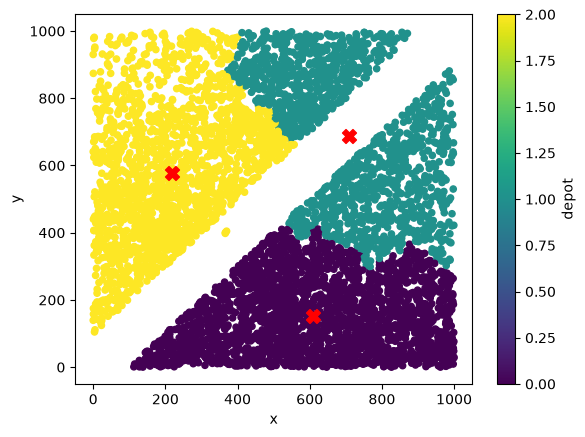

In [14]:
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt

# varikoiden lukumäärä
n_depots = 3

# luodaan hierarkkinen klusterointimalli
model = AgglomerativeClustering(n_clusters=n_depots)
model.fit(locations_df[["x", "y"]])

# päivitetään klusteriluokat dataframeen
labels = model.labels_
locations_df["depot"] = labels

# lasketaan klusterikeskukset
cluster_centers = locations_df.groupby("depot")[["x", "y"]].mean()
print("Varikoiden sijainnit:") 
print(cluster_centers)

# päivitetään klusterikeskusten dataframe
centers_df = pd.DataFrame(cluster_centers, columns=["x", "y"])

# Plotataan asiakkaiden sijainnit ja varikot
ax = locations_df.plot.scatter(x="x", y="y", c="depot", cmap="viridis"
)

ax.scatter(
    centers_df["x"],
    centers_df["y"],
    color="red",
    marker="X",
    s=100
)


Hierarkkinen klusterointi antaa klusterikeskuksen eri paikkoihin k-means-algoritmiin verrattuna. Kuvassa on plotattuna kolmen varikon paikat. Kokeilin `n_depots`-parametria myös arvoilla 5 ja 10, eli lisäsin klusterikeskusten määrää. Viiden varikon malli piirretään alla. Tarkempia tuloksia ja varikoiden sijainnit kerrotaan seuraavassa kappaleessa (1.5).

Varikoiden sijainnit:
                x           y
depot                        
0      218.178835  578.471885
1      466.876817  164.904182
2      813.649201  532.454781
3      820.723581  130.544730
4      591.929165  863.838825


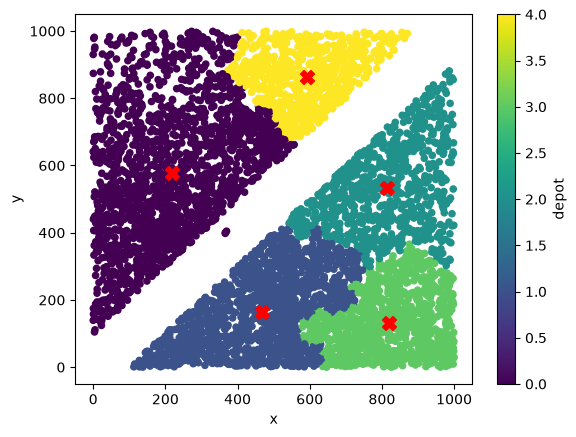

In [15]:
n_depots = 5

model = AgglomerativeClustering(n_clusters=n_depots)
model.fit(locations_df[["x", "y"]])

labels = model.labels_
locations_df["depot"] = labels

cluster_centers = locations_df.groupby("depot")[["x", "y"]].mean()
print("Varikoiden sijainnit:") 
print(cluster_centers)

centers_df = pd.DataFrame(cluster_centers, columns=["x", "y"])

ax = locations_df.plot.scatter(x="x", y="y", c="depot", cmap="viridis")

ax.scatter(centers_df["x"], centers_df["y"], color="red", marker="X", s=100)

### 1.5 Arviointi
*Evaluation*  

#### Varikoiden sijainnit
Jos varikoita on kolme, niiden koordinaatit käytössä olevalla asteikolla pitäisi olla seuraavat **k-means-algoritmin** mukaan:  
(196.689, 385.276),  
(548.746, 787.536) ja  
(700.477, 211.360).  

Viiden varikon optimaaliset sijainnit ovat seuraavat:  
(161.516, 497.294),  
(436.582, 148.416),  
(803.385, 151.574),  
(488.821, 825.338) ja  
(807.395, 531.379).  

**Hierarkkinen klusterointimalli** antoi eri sijainnit optimaalisille varikoille. Kolme varikkoa pitäisi sijoittaa seuraavasti:  
(607.735, 151.226),  
(709.979, 687.402) ja  
(218.179, 578.472).  

Viiden varikon optimaaliset sijainnit hierarkkisen klusterointimallin mukaan ovat:  
(218.179, 578.472),  
(466.877, 164.904),  
(813.649, 532.455),  
(820.724, 130.545) ja  
(591.929, 863.839).  

K-means- ja hierarkkinen klusterointi tuottavat toisistaan poikkeavat varikoiden sijainnit sekä kolmella että viidellä varikolla. Tämä johtuu siitä, että menetelmät muodostavat klusterit eri tavalla. K-means pyrkii sijoittamaan klusterikeskukset siten, että havaintojen etäisyys omasta keskuksesta olisi mahdollisimman pieni, kun taas agglomeratiivinen hierarkkinen klusterointi muodostaa klusterit yhdistämällä niitä vaiheittain.

Hierarkkisen klusteroinnin viiden varikon tuloksena ensimmäinen varikko palvelee pinta-alaltaan suurinta aluetta (violetti alue). Kymmenellä varikolla kokonaispinta-ala on tasaisemmin jakautunut varikoiden kesken, eikä vaikuta siltä, että yksi varikko dominoisi asiakkaiden lukumäärässä. Viiden varikon tapauksessa erot k-means-algoritmin ja hierarkkisen klusteroinnin välillä ovat selkeitä. Hierarkkisessa klusteroinnissa Klusterit näyttävät jakautuvan epätasaisemmin etenkin viiden varikon tapauksessa, jolloin yksi varikoista palvelee huomattavasti laajempaa aluetta kuin muut. Tämä osoittaa, että algoritmien erilaiset toimintaperiaatteet vaikuttavat siihen, miten asiakkaat ryhmitellään ja mihin varikot lopulta sijoittuvat.

### 1.6 Käyttöönotto
*Deployment*  

Klusterointimallin tuloksia voidaan hyödyntää asiakkaiden jakamiseen alueellisiin klustereihin ja varikoiden optimaalisten sijaintien suunnitteluun. Tulokset voidaan esittää visualisoimalla asiakkaat klustereittain ja merkitsemällä klusterikeskukset kartalle. Eri klusterimäärien avulla voidaan vertailla, miten varikoiden määrä vaikuttaa asiakkaiden jakautumiseen.  

Käyttöönotossa on tärkeää huomioida, että klusterikeskus on laskennallinen sijainti eikä välttämättä sellaisenaan sovellu todellisen varikon paikaksi. Lopullisessa varikoiden sijoittelussa tulisi huomioida myös varikon saavutettavuus, mahdolliset alueelliset rajoitukset ja kustannukset. Mallia voidaan tarvittaessa ajaa uudelleen, jos asiakasmäärä tai asiakkaiden sijainnit muuttuvat merkittävästi.

## Osa 2. Finding interesting relationships between product groups


Eli etsitään kiinnostavia suhteita tuoteryhmien välillä.

### 2.1 Tavoitteen määrittäminen

*Business Understanding*  

Tavoitteena on löytää drone-toimitusyrityksen myyntidatasta tuoteryhmiä, joita asiakkaat ostavat usein yhdessä. Association Rule Mining -menetelmän avulla voidaan selvittää, millaisia yhteyksiä eri tuoteryhmien välillä esiintyy.

Tuloksia voidaan hyödyntää esimerkiksi tuotteiden suosittelussa, tuoteryhmien yhdistämisessä kampanjoiksi sekä sopivien tuotepakettien suunnittelussa. Näin yritys voi hyödyntää asiakkaiden ostokäyttäytymisestä löytyviä yhteyksiä myynnin ja liikevaihdon kasvattamisessa.

### 2.2 Datan keräys ja tutkiminen

*Data Understanding*  

Käytetään `drone_prod_groups.csv`-datasettiä, joka sisältää tuotteiden myyntitietoja. Datasetissä yksi rivi vastaa yhtä ostotapahtumaa. ID-sarake sisältää tapahtuman tunnisteen ja sarakkeet Prod1..Prod20 kuvaavat eri tuoteryhmiä.

Tuoteryhmät ovat binäärisiä muuttujia. Arvo 1 tarkoittaa, että kyseistä tuoteryhmää ostettiin kyseisessä tapahtumassa, ja arvo 0 tarkoittaa, ettei tuoteryhmää ostettu.

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ladataan datasetti
prod_groups = pd.read_csv("datasets/drone_prod_groups.csv")

prod_groups

,ID,Prod1,Prod2,Prod3,Prod4,Prod5,Prod6,Prod7,Prod8,Prod9,...,Prod11,Prod12,Prod13,Prod14,Prod15,Prod16,Prod17,Prod18,Prod19,Prod20
0,1,0,0,0,0,0,0,0,0,1,...,0,0,0,0,1,0,0,0,0,1
1,2,0,1,0,0,0,0,0,0,1,...,0,0,0,0,1,1,1,1,1,1
2,3,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,1,1
3,4,1,0,0,1,0,0,0,0,0,...,1,0,0,0,0,0,0,0,1,1
4,5,0,0,0,0,0,0,0,0,1,...,0,0,0,0,1,0,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,99996,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
99996,99997,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
99997,99998,0,1,0,0,0,0,0,0,1,...,0,0,0,0,1,0,0,1,0,0
99998,99999,0,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,1,1


Datasetissä on 100 000 ostotapahtumaa.  

Tutkitaan seuraavaksi datasetin puuttuvia arvoja.

In [17]:
print("Puuttuvat arvot:")
print(prod_groups.isnull().sum())

Puuttuvat arvot:
ID         0
Prod1      0
 Prod2     0
 Prod3     0
 Prod4     0
 Prod5     0
 Prod6     0
 Prod7     0
 Prod8     0
 Prod9     0
 Prod10    0
 Prod11    0
 Prod12    0
 Prod13    0
 Prod14    0
 Prod15    0
 Prod16    0
 Prod17    0
 Prod18    0
 Prod19    0
 Prod20    0
dtype: int64


Puuttuvia arvoja ei ole missään sarakkeessa, joten koko datasettiä voidaan käyttää.

### 2.3 Datan valmistelu

*Data Preparation*  

ID-sarake ei ole tarpeellinen Association Rule Mining -menetelmässä, koska analyysissä tarkastellaan pelkästään sitä, mitä tuoteryhmiä samaan ostotapahtumaan kuuluu. Poistetaan ID ja jätetään analyysiin tuoteryhmät 1–20.  

Muunnetaan tuoteryhmien arvot boolean-muotoon, jossa True tarkoittaa tuoteryhmän sisältymistä ostotapahtumaan ja False sen puuttumista.  

In [18]:
# poistetaan ID
df = prod_groups.drop(columns="ID")

# muutetaan arvot boolean-muotoon
df = df.astype(bool)

df.head()

,Prod1,Prod2,Prod3,Prod4,Prod5,Prod6,Prod7,Prod8,Prod9,Prod10,Prod11,Prod12,Prod13,Prod14,Prod15,Prod16,Prod17,Prod18,Prod19,Prod20
0,False,False,False,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False,False,True
1,False,True,False,False,False,False,False,False,True,False,False,False,False,False,True,True,True,True,True,True
2,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,True
3,True,False,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,True
4,False,False,False,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False,True,True


Nyt dataa voi käyttää Apriori-algoritmissa.  

### 2.4 Mallinnus

*Modeling*  

Käytetään Apriori-algoritmia, jonka avulla etsitään tuoteryhmien yhdistelmiä, jotka esiintyvät ostotapahtumissa riittävän usein.  

Ensin etsitään frequent itemset -yhdistelmät. Käytetään support-raja-arvona (min_support) 0.1, jolloin yhdistelmän tulee esiintyä vähintään 10 prosentissa ostotapahtumista.

In [19]:
from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import association_rules

frequent_itemsets = apriori(df, min_support=0.1, use_colnames=True)
frequent_itemsets # tulostetaan usein esiintyvät tuotejoukot

,support,itemsets
0,0.10998,frozenset({Prod1})
1,0.13098,frozenset({ Prod2})
2,0.10459,frozenset({ Prod5})
3,0.13499,frozenset({ Prod7})
4,0.16179,frozenset({ Prod8})
5,0.19853,frozenset({ Prod9})
6,0.10848,frozenset({ Prod11})
7,0.15971,frozenset({ Prod12})
8,0.14557,frozenset({ Prod14})
9,0.11880,frozenset({ Prod15})


Luodaan assosiaatiosäännöt confidence-arvon perusteella.

In [20]:
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.5)
# lajitellaan säännöt laskevassa järjestyksessä
rules = rules.sort_values(by="confidence", ascending=False)
rules

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({ Prod15}),frozenset({ Prod9}),0.11880,0.19853,0.11145,0.938131,4.725388,1.0,0.087865,12.954372,0.894663,0.541335,0.922806,0.749754
2,frozenset({ Prod20}),frozenset({ Prod19}),0.14798,0.20626,0.13476,0.910664,4.415125,1.0,0.104238,8.884845,0.907849,0.613997,0.887449,0.782007
3,frozenset({ Prod19}),frozenset({ Prod20}),0.20626,0.14798,0.13476,0.653350,4.415125,1.0,0.104238,2.457869,0.974508,0.613997,0.593144,0.782007
1,frozenset({ Prod9}),frozenset({ Prod15}),0.19853,0.11880,0.11145,0.561376,4.725388,1.0,0.087865,2.009011,0.983664,0.541335,0.502243,0.749754


Saatiin yhteensä neljä sääntöä. Tarkastellaan niitä lift-arvolla (eli nosto), joka kertoo, kuinka paljon todennäköisemmin tuotteet esiintyvät yhdessä verrattuna tilanteeseen, jossa niiden esiintyminen olisi toisistaan riippumatonta. Toisin sanoen kuinka moninkertaiseksi toisen tuotteen (consequentes-sarake) esiintymisen todennäköisyys kasvaa, kun ensimmäinen tuote esiintyy.

In [21]:
rules_lift = association_rules(frequent_itemsets, metric="lift", min_threshold=2)

# järjestetään lift-arvon perusteella laskevaan järjestykseen
rules_lift = rules_lift.sort_values(by="lift", ascending=False)
rules_lift

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({ Prod15}),frozenset({ Prod9}),0.11880,0.19853,0.11145,0.938131,4.725388,1.0,0.087865,12.954372,0.894663,0.541335,0.922806,0.749754
1,frozenset({ Prod9}),frozenset({ Prod15}),0.19853,0.11880,0.11145,0.561376,4.725388,1.0,0.087865,2.009011,0.983664,0.541335,0.502243,0.749754
2,frozenset({ Prod20}),frozenset({ Prod19}),0.14798,0.20626,0.13476,0.910664,4.415125,1.0,0.104238,8.884845,0.907849,0.613997,0.887449,0.782007
3,frozenset({ Prod19}),frozenset({ Prod20}),0.20626,0.14798,0.13476,0.653350,4.415125,1.0,0.104238,2.457869,0.974508,0.613997,0.593144,0.782007


### 2.5 Arviointi
*Evaluation*  

Association Rule Mining -tuloksia arvioidaan erityisesti kolmen tunnusluvun avulla: support, confidence ja lift.  

- Support kertoo, kuinka suuri osuus kaikista ostotapahtumista sisältää sekä säännön lähtöjoukon (	antecedents) että seurausjoukon (consequents).
  
- Confidence kertoo, kuinka usein seurausjoukko esiintyy silloin, kun lähtöjoukko esiintyy.

- Lift kertoo, kuinka paljon lähtö- ja seurausjoukon yhteinen esiintyminen poikkeaa tilanteesta, jossa tuoteryhmät esiintyisivät toisistaan riippumatta. Mitä suurempi lift-arvo on, sitä voimakkaampi havaittu yhteys on.

Tuloksista löytyy kaksi vahvaa yhteyttä tuoteryhmien välillä. Vahvin yhteys on tuoteryhmien **Prod15 ja Prod9** välillä. Säännön Prod15 --> Prod9 support on 0,111, confidence 0,938 ja lift 4,725. Tämä tarkoittaa, että noin 11,1 % kaikista ostotapahtumista sisältää molemmat tuoteryhmät ja Prod15 ostaneista noin 93,8 % osti myös Prod9:ää. Lift-arvo 4,725 osoittaa, että tuoteryhmät esiintyvät yhdessä huomattavasti useammin kuin tilanteessa, jossa niiden välillä ei olisi yhteyttä.  

Toinen vahva yhteys on tuoteryhmien **Prod20 ja Prod19** välillä. Säännön Prod20 --> Prod19 support on 0,135, confidence 0,911 ja lift 4,415. Eli Prod20 ostaneista noin 91,1 % osti myös Prod19:ää. Myös tämän säännön lift-arvo osoittaa, että tuoteryhmien välillä on vahva yhteys.  

Sääntöjen suunnalla on merkitystä confidence-arvoon, koska se riippuu lähtökohtana olevasta tuoteryhmästä. Tulosten perusteella Prod15 → Prod9 ja Prod20 → Prod19 ovat vahvoja sääntöjä korkean confidencen ja selvästi yli yhden olevan lift-arvon perusteella. Näitä yhteyksiä voidaan hyödyntää esimerkiksi tuoteryhmien suosittelussa ja yhteisissä markkinointikampanjoissa.

Sääntöjen suunnalla on merkitystä confidence-arvon tulkinnassa. Esimerkiksi Prod15 --> Prod9 -säännön confidence on 93,8 %, kun taas Prod9 --> Prod15 -säännön confidence on 56,1 %. Lift on kuitenkin molemmissa suunnissa sama, eli 4,725. Tämä johtuu siitä, että confidence riippuu siitä, kumpaa tuoteryhmää käytetään lähtökohtana.  

Tulosten perusteella erityisesti säännöt Prod15 --> Prod9 ja Prod20 --> Prod19 ovat kiinnostavia. Niitä yhteyksiä voidaan hyödyntää tuotteiden markkinoinnissa, tarkemmin selitettynä seuraavassa kappaleessa.

### 2.6 Käyttöönotto

*Deployment*  

Tuloksia voidaan hyödyntää yrityksen myynnin kasvattamisessa esimerkiksi tuoteryhmien suosittelussa ja tuotteiden yhdistämisessä kampanjoiksi. Kun asiakas ostaa tiettyyn tuoteryhmään kuuluvan tuotteen, järjestelmä voisi suositella hänelle tuoteryhmää, joka esiintyy tutkimuksen perusteella usein saman ostotapahtuman yhteydessä.  

Tulosten perusteella järjestelmän tulisi siis suositella asiakkaalle tuotetta Prod9, kun hän ostaa tai on ostanut aiemmin tuotteen Prod15. Lisäksi tuotetta Prod20 ostaessa kannattaa suositella tuotetta Prod19. Nämä siksi, koska kyseisillä tuoteryhmillä on vahva yhteys. Näitä tuotteita voidaan tarjota pareina esimerkiksi kampanjoissa tai myydä tuotepaketteina. Eli yritys voisi tehdä tuotepaketit tuotteista Prod15 ja Prod9 sekä Prod20 ja Prod19, mikä voisi kasvattaa liikevaihtoa.